<a href="https://colab.research.google.com/github/fjnarvaezo1-dotcom/Lineal-regresion-machine-learning/blob/main/Tarea_3_%E2%80%93_Componente_pr%C3%A1ctico_Pr%C3%A1ctica_simulada_M%C3%A9todos_Estad%C3%ADsticos_en_la_Ciencia_de_Datos_y_Anal%C3%ADtica_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [10]:
import pandas as pd
import numpy as np
import json
import requests
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# - 1. Extraccion de Informacion y Dataframe, Ademas de limpieza de datos del Dataframe

In [11]:
ruta = "/content/drive/MyDrive/GESTIÓN DE PROYECTOS PARA LA ANALÍTICA - (203008074A_2204)/Anexo 1 - Base de Datos dynamic_pricing (3) (1).csv"

## - 1.1 Extraccion de Dataframe limpieza y ajuste de informacion

In [12]:
dtframe = pd.read_csv(ruta)
dataframe = pd.DataFrame(data=dtframe)
dataframe.head(2000)

,Number_of_Riders,Number_of_Drivers,Location_Category,Customer_Loyalty_Status,Number_of_Past_Rides,Average_Ratings,Time_of_Booking,Vehicle_Type,Expected_Ride_Duration,Historical_Cost_of_Ride
0,90,45,Urban,Silver,13,4.47,Night,Premium,90,284.257273
1,58,39,Suburban,Silver,72,4.06,Evening,Economy,43,173.874753
2,42,31,Rural,Silver,0,3.99,Afternoon,Premium,76,329.795469
3,89,28,Rural,Regular,67,4.31,Afternoon,Premium,134,470.201232
4,78,22,Rural,Regular,74,3.77,Afternoon,Economy,149,579.681422
...,...,...,...,...,...,...,...,...,...,...
995,33,23,Urban,Gold,24,4.21,Morning,Premium,11,91.389526
996,84,29,Urban,Regular,92,4.55,Morning,Premium,94,424.155987
997,44,6,Suburban,Gold,80,4.13,Night,Premium,40,157.364830
998,53,27,Suburban,Regular,78,3.63,Night,Premium,58,279.095048


## - 1.2 Eliminar valores Null y limpiar la informacion del dataframe para hacer el analizis y ajustar el modelo

In [13]:
dataframe = dataframe.dropna()
dataframe = dataframe.isna().sum()
print(dataframe)


Number_of_Riders           0
Number_of_Drivers          0
Location_Category          0
Customer_Loyalty_Status    0
Number_of_Past_Rides       0
Average_Ratings            0
Time_of_Booking            0
Vehicle_Type               0
Expected_Ride_Duration     0
Historical_Cost_of_Ride    0
dtype: int64


 **Se logra confirmar que el dataframe tiene los datos, pulcros y sin datos en null por lo cual se analizara ahora si el proceso de regresion lineal con base a la informacion suministrada**

In [14]:
print(dataframe.dtypes)
print(dataframe.info())

int64
<class 'pandas.core.series.Series'>
Index: 10 entries, Number_of_Riders to Historical_Cost_of_Ride
Series name: None
Non-Null Count  Dtype
--------------  -----
10 non-null     int64
dtypes: int64(1)
memory usage: 460.0+ bytes
None


### **El Dataframe es un dataframe con todos los valores numericos por lo visto, para iniciar el proceso de regresion lineal y la informacion**

# 2. Ajuste del modelo de regresión lineal *múltiple*

## - 2.1 Definir el modelo con Average_Ratings (como continua) como variable dependiente y: Number_of_Riders, Expected_Ride_Duration, Customer_Loyalty_Status


In [15]:
dtframe.corr(numeric_only=True)['Average_Ratings'].sort_values()

,Average_Ratings
Number_of_Past_Rides,-0.064734
Expected_Ride_Duration,-0.016968
Historical_Cost_of_Ride,-0.001063
Number_of_Riders,0.008572
Number_of_Drivers,0.041204
Average_Ratings,1.000000


### Modelo de coorrelacion de pearson

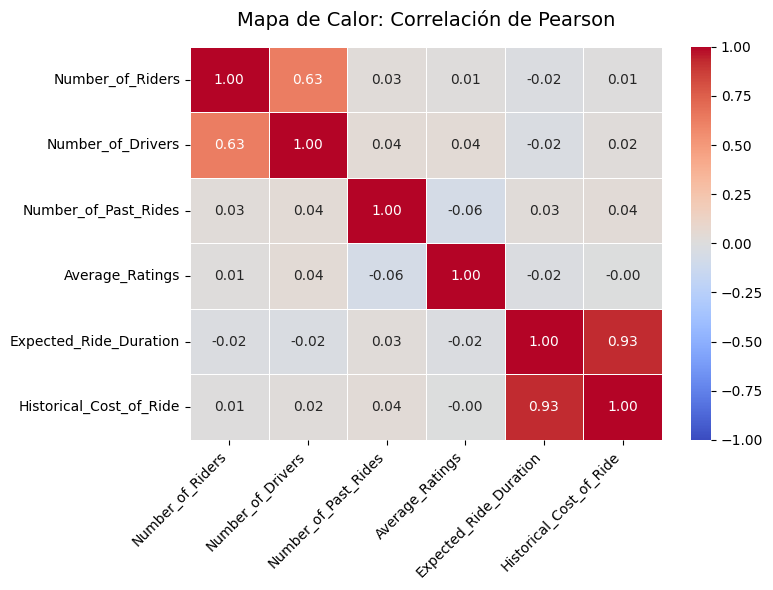

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

# Usamos dtframe que contiene el DataFrame original en vez de la Serie "dataframe"
matriz_correlacion = dtframe.corr(numeric_only=True)

plt.figure(figsize=(8, 6))

sns.heatmap(
    matriz_correlacion,
    annot=True,          # Muestra el valor numérico exacto en cada celda
    cmap='coolwarm',     # Paleta de colores: azul (negativo), rojo (positivo)
    fmt='.2f',           # Redondea los valores a 2 decimales
    vmin=-1, vmax=1,     # Fija los límites matemáticos de Pearson (-1 a 1)
    linewidths=0.5       # Agrega líneas de separación entre celdas
)

plt.title('Mapa de Calor: Correlación de Pearson', fontsize=14, pad=15)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

plt.show()

In [17]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import MinMaxScaler
import pandas as pd

# Reestablecemos el DataFrame limpio a partir del original 'dtframe'
dataframe_clean = dtframe.dropna()

# Extraemos las variables independientes (X) y la variable dependiente (y)
X = dataframe_clean[['Number_of_Riders', 'Expected_Ride_Duration', 'Customer_Loyalty_Status']]
y = dataframe_clean['Average_Ratings']

# Convertimos las variables categóricas a variables dummy
X = pd.get_dummies(X, columns=['Customer_Loyalty_Status'], drop_first=True)

# Dividimos el conjunto de datos
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Escalamos los datos independientes
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Entrenamos el modelo de regresión lineal
modelo = LinearRegression()
modelo.fit(X_train_scaled, y_train)

print("Modelo entrenado exitosamente. Coeficientes:", modelo.coef_)

Modelo entrenado exitosamente. Coeficientes: [-0.01035241 -0.06226049  0.01159575  0.06386385]


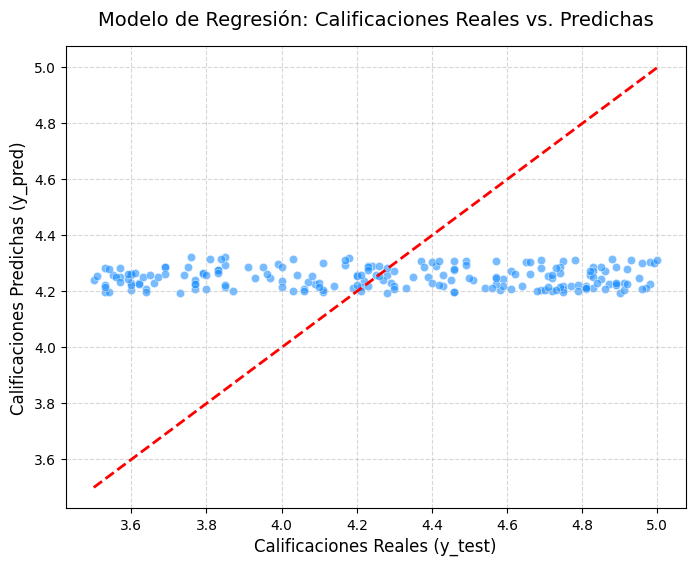

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

y_pred = modelo.predict(X_test_scaled)

plt.figure(figsize=(8, 6))

sns.scatterplot(x=y_test, y=y_pred, alpha=0.6, color='dodgerblue')

min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2)

plt.title('Modelo de Regresión: Calificaciones Reales vs. Predichas', fontsize=14, pad=15)
plt.xlabel('Calificaciones Reales (y_test)', fontsize=12)
plt.ylabel('Calificaciones Predichas (y_pred)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)

plt.show()

##  - 2.2 Ecuación del modelo estimado. Coeficientes β e interpretación contextual. Significancia estadística (valores p). Métricas de ajuste: R², R² ajustado, RSE

In [19]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import MinMaxScaler
import statsmodels.api as sm
import pandas as pd
import numpy as np

# 1. Limpieza a partir del DataFrame original intacto 'dtframe'
dataframe_clean = dtframe.dropna().copy()

# 2. Extracción de variables independientes (X) y dependiente (y)
X = dataframe_clean[['Number_of_Riders', 'Expected_Ride_Duration', 'Customer_Loyalty_Status']]
y = dataframe_clean['Average_Ratings']

# 3. Conversión de variables categóricas a dummy (asegurando tipo numérico)
X = pd.get_dummies(X, columns=['Customer_Loyalty_Status'], drop_first=True, dtype=float)

# Guardamos los nombres de las columnas para las etiquetas del reporte
feature_names = X.columns.tolist()

# 4. División del conjunto de datos
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 5. Escalado MinMaxScaler
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 6. Entrenamiento en Scikit-Learn
modelo = LinearRegression()
modelo.fit(X_train_scaled, y_train)

# 7. Ajuste equivalente en Statsmodels para extraer p-values, R2 ajustado y RSE
X_train_sm = pd.DataFrame(X_train_scaled, columns=feature_names, index=y_train.index)
X_train_sm = sm.add_constant(X_train_sm)  # Agrega el intercepto (Beta_0)
modelo_ols = sm.OLS(y_train, X_train_sm).fit()

# --- IMPRESIÓN DE RESULTADOS PARA TU INFORME ---

# A. Ecuación del modelo estimado
ecuacion = f"Average_Ratings = {modelo.intercept_:.4f}"
for nombre, coef in zip(feature_names, modelo.coef_):
    signo = "+" if coef >= 0 else "-"
    ecuacion += f" {signo} {abs(coef):.4f}*({nombre})"

print("=== 1. ECUACIÓN DEL MODELO ESTIMADO ===")
print(ecuacion)
print("\n" + "="*50 + "\n")

# B. Tabla de Coeficientes Beta y Valores p
tabla_resumen = pd.DataFrame({
    'Coeficiente (Beta)': modelo_ols.params,
    'Error Estándar': modelo_ols.bse,
    'Estadístico t': modelo_ols.tvalues,
    'Valor p': modelo_ols.pvalues,
    '¿Significativo (p < 0.05)?': np.where(modelo_ols.pvalues < 0.05, 'Sí', 'No')
})

print("=== 2 y 3. COEFICIENTES BETA Y SIGNIFICANCIA ESTADÍSTICA ===")
print(tabla_resumen.round(4))
print("\n" + "="*50 + "\n")

# C. Métricas de Ajuste (R2, R2 Ajustado y RSE)
r2 = modelo_ols.rsquared
r2_adj = modelo_ols.rsquared_adj
rse = np.sqrt(modelo_ols.mse_resid)  # Raíz del cuadrado medio del residuo

print("=== 4. MÉTRICAS DE AJUSTE DEL MODELO (ENTRENAMIENTO) ===")
print(f"R² (Coeficiente de determinación): {r2:.6f} ({r2*100:.2f}%)")
print(f"R² Ajustado:                       {r2_adj:.6f} ({r2_adj*100:.2f}%)")
print(f"RSE (Error Estándar Residual):     {rse:.4f} puntos de calificación")

=== 1. ECUACIÓN DEL MODELO ESTIMADO ===
Average_Ratings = 4.2612 - 0.0104*(Number_of_Riders) - 0.0623*(Expected_Ride_Duration) + 0.0116*(Customer_Loyalty_Status_Regular) + 0.0639*(Customer_Loyalty_Status_Silver)


=== 2 y 3. COEFICIENTES BETA Y SIGNIFICANCIA ESTADÍSTICA ===
                                 Coeficiente (Beta)  Error Estándar  \
const                                        4.2612          0.0468   
Number_of_Riders                            -0.0104          0.0521   
Expected_Ride_Duration                      -0.0623          0.0530   
Customer_Loyalty_Status_Regular              0.0116          0.0383   
Customer_Loyalty_Status_Silver               0.0639          0.0368   

                                 Estadístico t  Valor p  \
const                                  91.1459   0.0000   
Number_of_Riders                       -0.1985   0.8427   
Expected_Ride_Duration                 -1.1749   0.2404   
Customer_Loyalty_Status_Regular         0.3030   0.7620   
Cus

## - 2.3 Diagnóstico de colinealidad y observaciones *influyentes*

=== 2.3.1 MATRIZ DE CORRELACIONES ENTRE PREDICTORES ===
                                 Number_of_Riders  Expected_Ride_Duration  \
Number_of_Riders                           1.0000                 -0.0156   
Expected_Ride_Duration                    -0.0156                  1.0000   
Customer_Loyalty_Status_Regular            0.0754                  0.0104   
Customer_Loyalty_Status_Silver            -0.0381                 -0.0147   

                                 Customer_Loyalty_Status_Regular  \
Number_of_Riders                                          0.0754   
Expected_Ride_Duration                                    0.0104   
Customer_Loyalty_Status_Regular                           1.0000   
Customer_Loyalty_Status_Silver                           -0.5155   

                                 Customer_Loyalty_Status_Silver  
Number_of_Riders                                        -0.0381  
Expected_Ride_Duration                                  -0.0147  
Customer_Loyalty_St

/tmp/ipykernel_1667/2104566864.py:84: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=vif_predictores, x='VIF', y='Variable', palette='Blues_r', ax=axes[0, 1])


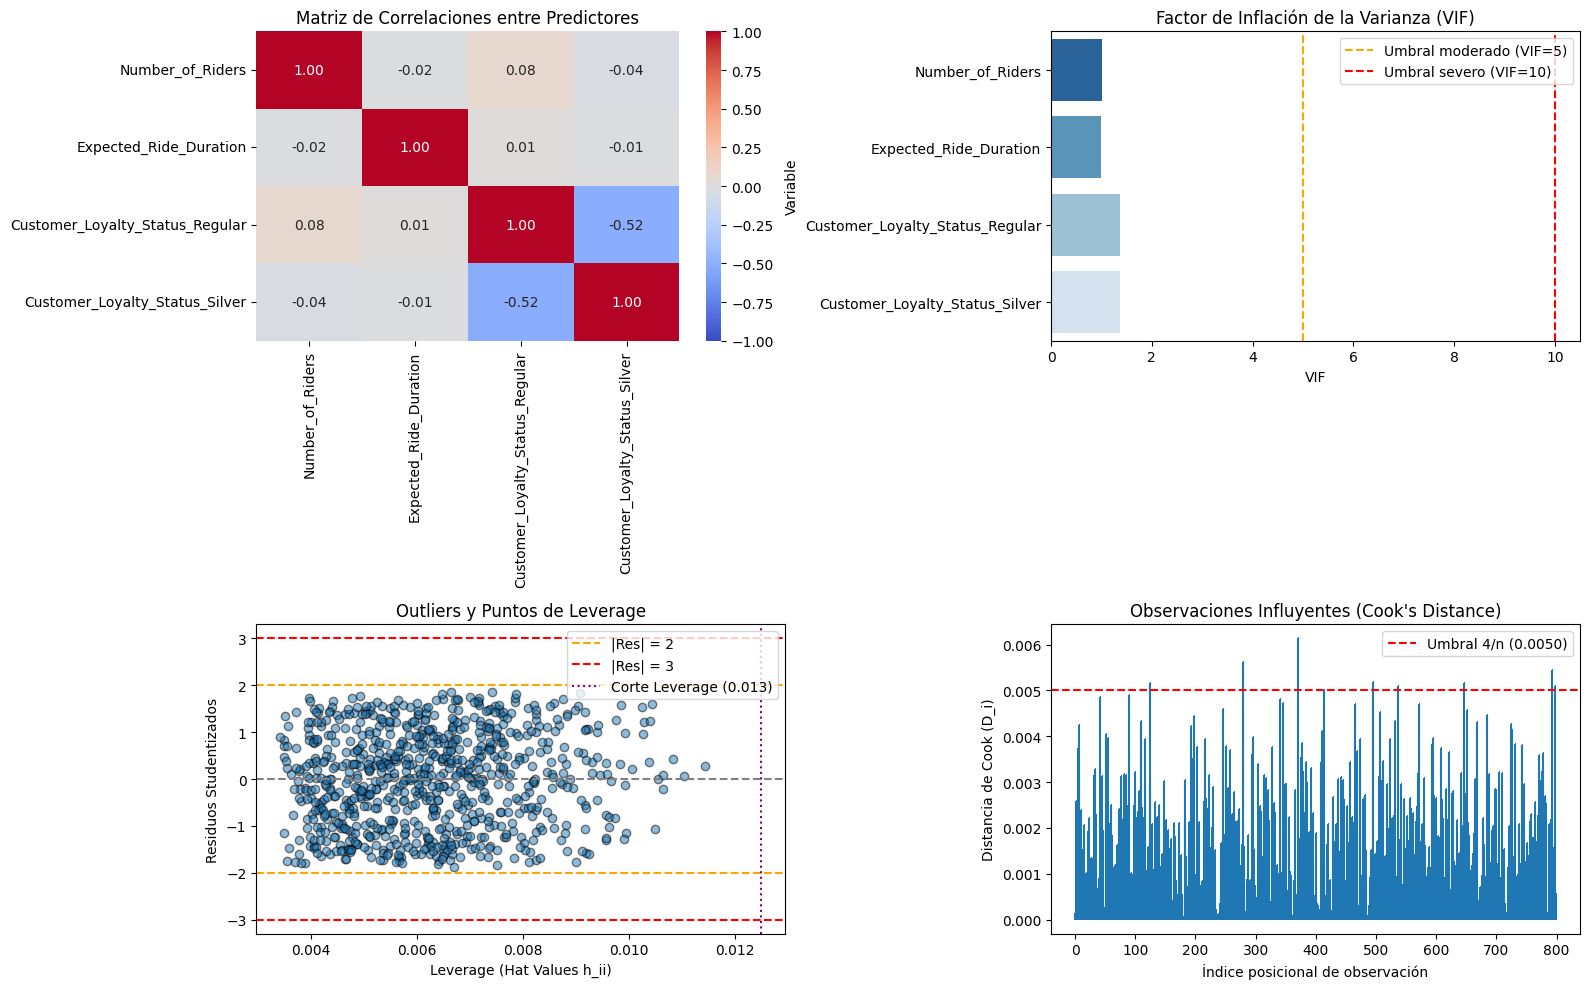

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

# ==============================================================================
# 1. MATRIZ DE CORRELACIONES Y FACTOR DE INFLACIÓN DE LA VARIANZA (VIF)
# ==============================================================================
X_predictores = X_train_sm.drop(columns=['const'])
matriz_corr = X_predictores.corr()

print("=== 2.3.1 MATRIZ DE CORRELACIONES ENTRE PREDICTORES ===")
print(matriz_corr.round(4))
print("\n" + "="*55 + "\n")

# Cálculo de VIF (incluyendo la constante en la matriz base pero reportando predictores)
vif_data = pd.DataFrame()
vif_data["Variable"] = X_train_sm.columns
vif_data["VIF"] = [variance_inflation_factor(X_train_sm.values, i) for i in range(X_train_sm.shape[1])]
vif_predictores = vif_data[vif_data["Variable"] != "const"].reset_index(drop=True)

print("=== 2.3.2 FACTOR DE INFLACIÓN DE LA VARIANZA (VIF) ===")
print(vif_predictores.round(4))
print("\n" + "="*55 + "\n")

# ==============================================================================
# 2. IDENTIFICACIÓN DE OUTLIERS, LEVERAGE Y OBSERVACIONES INFLUYENTES
# ==============================================================================
influencia = modelo_ols.get_influence()

# Métricas de diagnóstico por observación
residuos_estandarizados = influencia.resid_studentized_internal
residuos_studentizados = influencia.resid_studentized_external
hat_values = influencia.hat_matrix_diag
cooks_d = influencia.cooks_distance[0]
dfbetas = influencia.dfbetas

# Umbrales teóricos clásicos
n = len(y_train)
k = X_predictores.shape[1]  # k = 4 predictores
umbral_leverage = (2 * (k + 1)) / n
umbral_cook = 4 / n
umbral_dfbeta = 2 / np.sqrt(n)

df_diag = pd.DataFrame({
    'Y_Real': y_train,
    'Y_Predicho': modelo_ols.fittedvalues,
    'Res_Estandarizado': residuos_estandarizados,
    'Res_Studentizado': residuos_studentizados,
    'Leverage (h_ii)': hat_values,
    'Cooks_D': cooks_d,
    'Max_Abs_DFBETA': np.max(np.abs(dfbetas[:, 1:]), axis=1) # Excluye intercepto
}, index=y_train.index)

outliers_mod = df_diag[df_diag['Res_Studentizado'].abs() > 2]
outliers_sev = df_diag[df_diag['Res_Studentizado'].abs() > 3]
alto_leverage = df_diag[df_diag['Leverage (h_ii)'] > umbral_leverage]
influyentes_cook = df_diag[df_diag['Cooks_D'] > umbral_cook]
influyentes_dfbeta = df_diag[df_diag['Max_Abs_DFBETA'] > umbral_dfbeta]

print("=== 2.3.3 RESUMEN DE CASOS PROBLEMÁTICOS DETECTADOS ===")
print(f"Total de observaciones de entrenamiento (n): {n}")
print(f"- Outliers moderados (|Res. Studentizado| > 2): {len(outliers_mod)} casos")
print(f"- Outliers severos (|Res. Studentizado| > 3):   {len(outliers_sev)} casos")
print(f"- Puntos de alto leverage (h_ii > {umbral_leverage:.4f}):     {len(alto_leverage)} casos")
print(f"- Influyentes por Distancia de Cook (D_i > {umbral_cook:.4f}): {len(influyentes_cook)} casos")
print(f"- Influyentes por DFBETAs (|DFBETA| > {umbral_dfbeta:.4f}):  {len(influyentes_dfbeta)} casos")

print("\nTop 5 observaciones más influyentes según Distancia de Cook:")
print(df_diag.sort_values(by='Cooks_D', ascending=False).head(5).round(4))

# ==============================================================================
# 3. GRÁFICOS DE DIAGNÓSTICO DE COLINEALIDAD E INFLUENCIA
# ==============================================================================
fig, axes = plt.subplots(2, 2, figsize=(16, 10 ))

# Gráfico 1: Mapa de calor de correlaciones
sns.heatmap(matriz_corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt=".2f", ax=axes[0, 0])
axes[0, 0].set_title("Matriz de Correlaciones entre Predictores")

# Gráfico 2: VIF por predictor
sns.barplot(data=vif_predictores, x='VIF', y='Variable', palette='Blues_r', ax=axes[0, 1])
axes[0, 1].axvline(5, color='orange', linestyle='--', label='Umbral moderado (VIF=5)')
axes[0, 1].axvline(10, color='red', linestyle='--', label='Umbral severo (VIF=10)')
axes[0, 1].set_title("Factor de Inflación de la Varianza (VIF)")
axes[0, 1].legend()

# Gráfico 3: Residuos Studentizados vs Leverage
axes[1, 0].scatter(hat_values, residuos_studentizados, alpha=0.5, edgecolors='k')
axes[1, 0].axhline(0, color='gray', linestyle='--')
axes[1, 0].axhline(2, color='orange', linestyle='--', label='|Res| = 2')
axes[1, 0].axhline(-2, color='orange', linestyle='--')
axes[1, 0].axhline(3, color='red', linestyle='--', label='|Res| = 3')
axes[1, 0].axhline(-3, color='red', linestyle='--')
axes[1, 0].axvline(umbral_leverage, color='purple', linestyle=':', label=f'Corte Leverage ({umbral_leverage:.3f})')
axes[1, 0].set_xlabel("Leverage (Hat Values h_ii)")
axes[1, 0].set_ylabel("Residuos Studentizados")
axes[1, 0].set_title("Outliers y Puntos de Leverage")
axes[1, 0].legend(loc='best')

# Gráfico 4: Distancia de Cook
axes[1, 1].stem(range(n), cooks_d, markerfmt=",", basefmt=" ")
axes[1, 1].axhline(umbral_cook, color='red', linestyle='--', label=f'Umbral 4/n ({umbral_cook:.4f})')
axes[1, 1].set_xlabel("Índice posicional de observación")
axes[1, 1].set_ylabel("Distancia de Cook (D_i)")
axes[1, 1].set_title("Observaciones Influyentes (Cook's Distance)")
axes[1, 1].legend()

plt.tight_layout()
plt.show()

## - 2.4 Evaluación de supuestos del modelo

=== 2.4 PRUEBAS FORMALES DE SUPUESTOS DEL MODELO ===
1. Normalidad (Shapiro-Wilk):       Estadístico W = 0.9622 | Valor p = 0.000000
   -> Conclusión: Viola normalidad (p < 0.05)

2. Homoscedasticidad (Breusch-Pagan): Estadístico LM = 9.7037 | Valor p = 0.045726
   -> Conclusión: Presenta heteroscedasticidad (p < 0.05)

3. Independencia (Durbin-Watson):    Estadístico DW = 1.9276
   -> Conclusión: Ausencia de autocorrelación (DW cercano a 2.0)


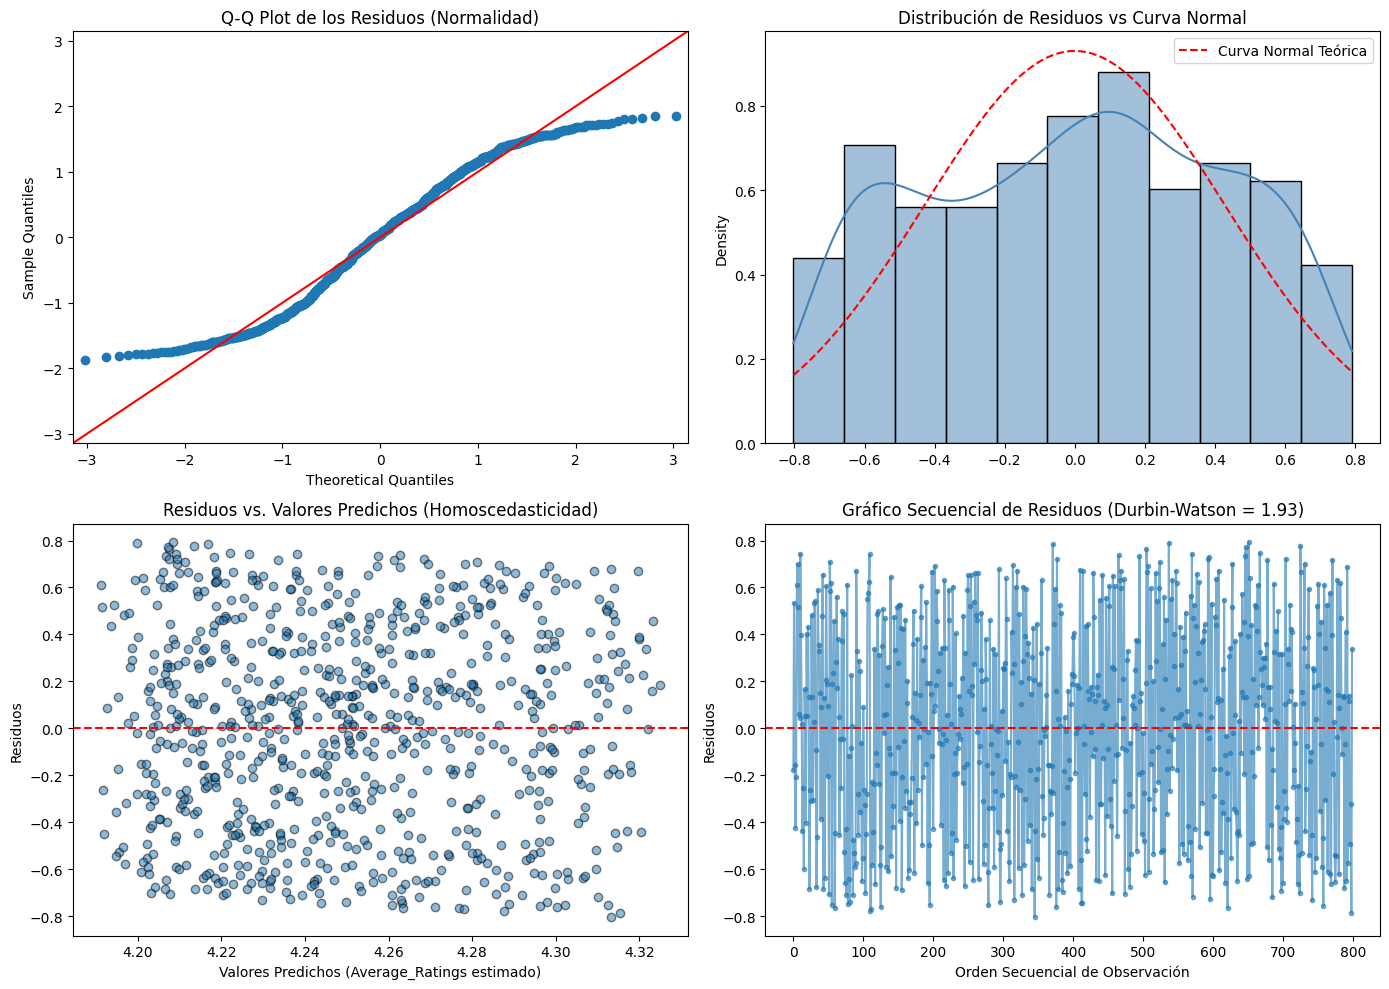

In [24]:
import scipy.stats as stats
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson

residuos = modelo_ols.resid
predichos = modelo_ols.fittedvalues

# ==============================================================================
# 1. PRUEBAS ESTADÍSTICAS DE LOS SUPUESTOS
# ==============================================================================
# A. Normalidad: Prueba de Shapiro-Wilk
shapiro_stat, shapiro_p = stats.shapiro(residuos)

# B. Homoscedasticidad: Prueba de Breusch-Pagan
bp_lm, bp_lm_pvalue, bp_fvalue, bp_f_pvalue = het_breuschpagan(residuos, modelo_ols.model.exog)

# C. Independencia: Estadístico de Durbin-Watson
dw_stat = durbin_watson(residuos)

print("=== 2.4 PRUEBAS FORMALES DE SUPUESTOS DEL MODELO ===")
print(f"1. Normalidad (Shapiro-Wilk):       Estadístico W = {shapiro_stat:.4f} | Valor p = {shapiro_p:.6f}")
print(f"   -> Conclusión: {'Cumple normalidad (p >= 0.05)' if shapiro_p >= 0.05 else 'Viola normalidad (p < 0.05)'}")

print(f"\n2. Homoscedasticidad (Breusch-Pagan): Estadístico LM = {bp_lm:.4f} | Valor p = {bp_lm_pvalue:.6f}")
print(f"   -> Conclusión: {'Cumple homoscedasticidad (p >= 0.05)' if bp_lm_pvalue >= 0.05 else 'Presenta heteroscedasticidad (p < 0.05)'}")

print(f"\n3. Independencia (Durbin-Watson):    Estadístico DW = {dw_stat:.4f}")
print(f"   -> Conclusión: {'Ausencia de autocorrelación (DW cercano a 2.0)' if 1.5 <= dw_stat <= 2.5 else 'Posible autocorrelación de residuos'}")

# ==============================================================================
# 2. GRÁFICOS DE EVALUACIÓN DE SUPUESTOS
# ==============================================================================
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Gráfico 1: Q-Q Plot de residuos
sm.qqplot(residuos, line='45', fit=True, ax=axes[0, 0])
axes[0, 0].set_title("Q-Q Plot de los Residuos (Normalidad)")

# Gráfico 2: Distribución de los residuos (Histograma + KDE)
sns.histplot(residuos, kde=True, stat="density", color="steelblue", ax=axes[0, 1])
x_norm = np.linspace(residuos.min(), residuos.max(), 100)
axes[0, 1].plot(x_norm, stats.norm.pdf(x_norm, residuos.mean(), residuos.std()), 'r--', label='Curva Normal Teórica')
axes[0, 1].set_title("Distribución de Residuos vs Curva Normal")
axes[0, 1].legend()

# Gráfico 3: Residuos vs Valores Predichos (Homoscedasticidad)
axes[1, 0].scatter(predichos, residuos, alpha=0.5, edgecolors='k')
axes[1, 0].axhline(0, color='red', linestyle='--')
axes[1, 0].set_xlabel("Valores Predichos (Average_Ratings estimado)")
axes[1, 0].set_ylabel("Residuos")
axes[1, 0].set_title("Residuos vs. Valores Predichos (Homoscedasticidad)")

# Gráfico 4: Gráfico Secuencial de Residuos (Independencia)
axes[1, 1].plot(range(len(residuos)), residuos.values, marker='o', linestyle='-', markersize=3, alpha=0.6)
axes[1, 1].axhline(0, color='red', linestyle='--')
axes[1, 1].set_xlabel("Orden Secuencial de Observación")
axes[1, 1].set_ylabel("Residuos")
axes[1, 1].set_title(f"Gráfico Secuencial de Residuos (Durbin-Watson = {dw_stat:.2f})")

plt.tight_layout()
plt.show()

## - 2.5 Remediación de violaciones

In [25]:
# ==============================================================================
# 1. TRANSFORMACIONES SOBRE LA VARIABLE RESPUESTA (LOGARÍTMICA Y BOX-COX)
# ==============================================================================
# A. Transformación Logarítmica: ln(y)
y_train_log = np.log(y_train)
modelo_log = sm.OLS(y_train_log, X_train_sm).fit()

# B. Transformación Box-Cox (requiere y > 0, lo cual se cumple en Average_Ratings)
y_train_boxcox, lambda_optimo = stats.boxcox(y_train)
y_train_boxcox_s = pd.Series(y_train_boxcox, index=y_train.index)
modelo_boxcox = sm.OLS(y_train_boxcox_s, X_train_sm).fit()

print("=== 2.5.1 REMEDIACIÓN MEDIANTE TRANSFORMACIONES (LOG Y BOX-COX) ===")
print(f"Lambda óptimo encontrado por Box-Cox: {lambda_optimo:.4f}\n")

comp_transformaciones = pd.DataFrame({
    'Métrica': ['R²', 'R² Ajustado', 'Valor p (F-stat)', 'Shapiro-Wilk (p-valor)', 'Breusch-Pagan (p-valor)'],
    'OLS Original (y)': [
        modelo_ols.rsquared, modelo_ols.rsquared_adj, modelo_ols.f_pvalue,
        stats.shapiro(modelo_ols.resid)[1], het_breuschpagan(modelo_ols.resid, X_train_sm)[1]
    ],
    'OLS Logarítmico ln(y)': [
        modelo_log.rsquared, modelo_log.rsquared_adj, modelo_log.f_pvalue,
        stats.shapiro(modelo_log.resid)[1], het_breuschpagan(modelo_log.resid, X_train_sm)[1]
    ],
    'OLS Box-Cox': [
        modelo_boxcox.rsquared, modelo_boxcox.rsquared_adj, modelo_boxcox.f_pvalue,
        stats.shapiro(modelo_boxcox.resid)[1], het_breuschpagan(modelo_boxcox.resid, X_train_sm)[1]
    ]
})
print(comp_transformaciones.round(6).to_string(index=False))
print("\n" + "="*65 + "\n")

# ==============================================================================
# 2. MODELO LINEAL ROBUSTO (RLM CON M-ESTIMADOR DE HUBER)
# ==============================================================================
modelo_rlm = sm.RLM(y_train, X_train_sm, M=sm.robust.norms.HuberT()).fit()

print("=== 2.5.2 COMPARACIÓN: OLS CLÁSICO VS. REGRESIÓN ROBUSTA (RLM) ===")
tabla_ols_vs_rlm = pd.DataFrame({
    'Beta_OLS': modelo_ols.params,
    'SE_OLS': modelo_ols.bse,
    'p_val_OLS': modelo_ols.pvalues,
    'Beta_RLM (Robusto)': modelo_rlm.params,
    'SE_RLM': modelo_rlm.bse,
    'p_val_RLM': modelo_rlm.pvalues
})
print(tabla_ols_vs_rlm.round(4))

=== 2.5.1 REMEDIACIÓN MEDIANTE TRANSFORMACIONES (LOG Y BOX-COX) ===
Lambda óptimo encontrado por Box-Cox: 1.1256

                Métrica  OLS Original (y)  OLS Logarítmico ln(y)  OLS Box-Cox
                     R²          0.006224               0.006089     0.006241
            R² Ajustado          0.001224               0.001088     0.001241
       Valor p (F-stat)          0.290433               0.301770     0.288994
 Shapiro-Wilk (p-valor)          0.000000               0.000000     0.000000
Breusch-Pagan (p-valor)          0.045726               0.059454     0.044486


=== 2.5.2 COMPARACIÓN: OLS CLÁSICO VS. REGRESIÓN ROBUSTA (RLM) ===
                                 Beta_OLS  SE_OLS  p_val_OLS  \
const                              4.2612  0.0468     0.0000   
Number_of_Riders                  -0.0104  0.0521     0.8427   
Expected_Ride_Duration            -0.0623  0.0530     0.2404   
Customer_Loyalty_Status_Regular    0.0116  0.0383     0.7620   
Customer_Loyalty_Status_Silve

## - 2.6 Remuestreo para validación: Bootstrap

=== 2.6 VALIDACIÓN BOOTSTRAP (1000 ITERACIONES) VS. INFERENCIA CLÁSICA ===
                                 Beta_OLS  Media_Boot  Sesgo_Boot  SE_OLS  \
const                              4.2612      4.2601     -0.0012  0.0468   
Number_of_Riders                  -0.0104     -0.0098      0.0006  0.0521   
Expected_Ride_Duration            -0.0623     -0.0624     -0.0002  0.0530   
Customer_Loyalty_Status_Regular    0.0116      0.0120      0.0004  0.0383   
Customer_Loyalty_Status_Silver     0.0639      0.0665      0.0026  0.0368   

                                 SE_Boot  IC95_OLS_Inf  IC95_OLS_Sup  \
const                             0.0447        4.1695        4.3530   
Number_of_Riders                  0.0536       -0.1127        0.0920   
Expected_Ride_Duration            0.0512       -0.1663        0.0418   
Customer_Loyalty_Status_Regular   0.0362       -0.0635        0.0867   
Customer_Loyalty_Status_Silver    0.0357       -0.0084        0.1361   

                             

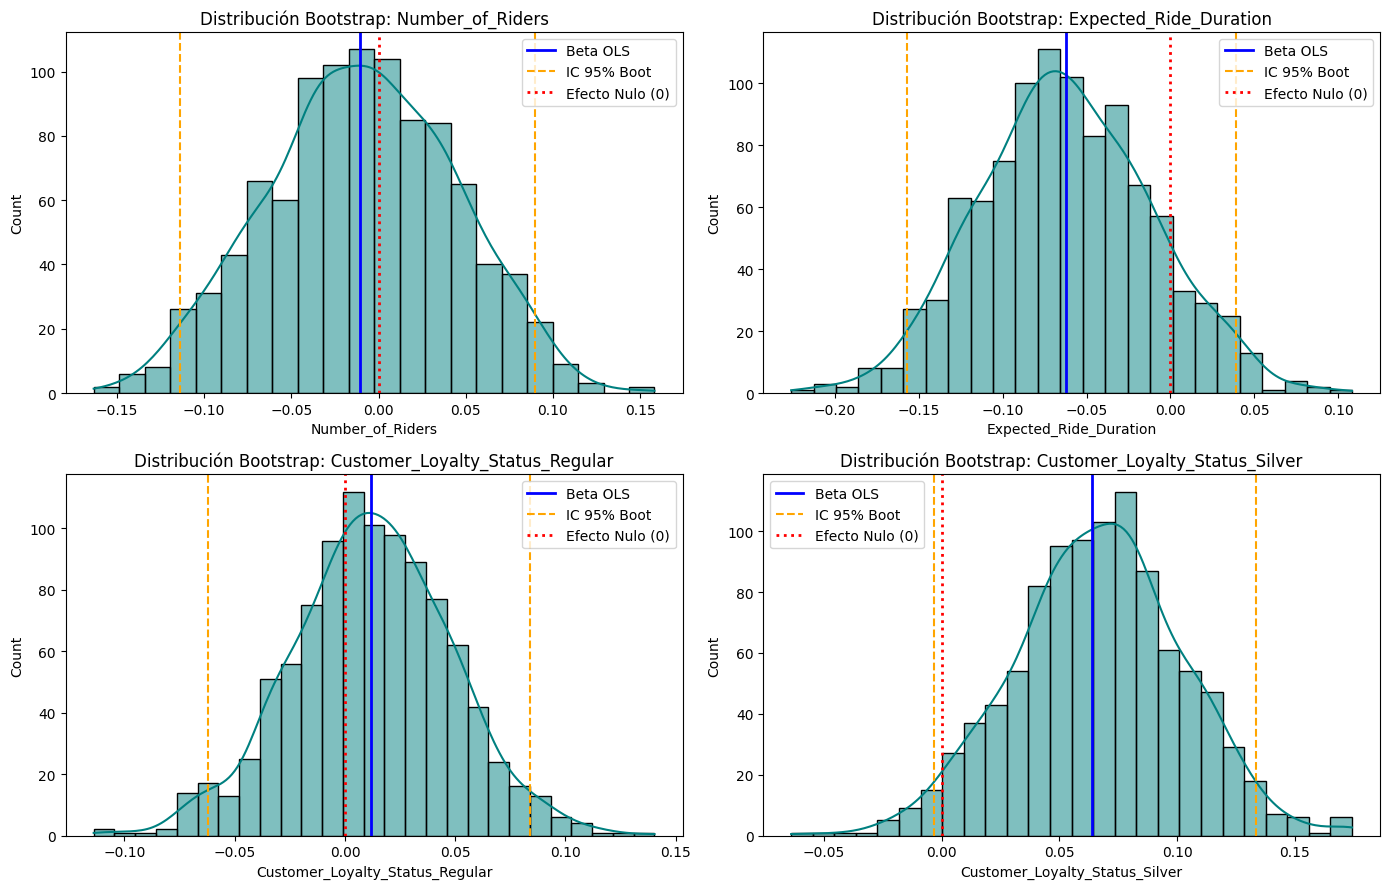

In [26]:
# ==============================================================================
# REMUESTREO BOOTSTRAP (1000 ITERACIONES) SOBRE LOS COEFICIENTES
# ==============================================================================
np.random.seed(42)
n_boot = 1000
n_obs = len(y_train)
boot_betas = np.zeros((n_boot, X_train_sm.shape[1]))

X_values = X_train_sm.values
y_values = y_train.values

for i in range(n_boot):
    # Muestreo aleatorio con reemplazo
    indices = np.random.choice(n_obs, size=n_obs, replace=True)
    X_b = X_values[indices]
    y_b = y_values[indices]
    # Solución por mínimos cuadrados en la muestra bootstrap
    beta_b, _, _, _ = np.linalg.lstsq(X_b, y_b, rcond=None)
    boot_betas[i, :] = beta_b

df_boot = pd.DataFrame(boot_betas, columns=X_train_sm.columns)

# Intervalos de confianza clásicos (OLS al 95%) vs Empíricos Bootstrap (Percentiles 2.5% y 97.5%)
ic_ols = modelo_ols.conf_int(alpha=0.05)
ic_boot_inf = df_boot.quantile(0.025)
ic_boot_sup = df_boot.quantile(0.975)

tabla_bootstrap = pd.DataFrame({
    'Beta_OLS': modelo_ols.params,
    'Media_Boot': df_boot.mean(),
    'Sesgo_Boot': df_boot.mean() - modelo_ols.params,
    'SE_OLS': modelo_ols.bse,
    'SE_Boot': df_boot.std(),
    'IC95_OLS_Inf': ic_ols[0],
    'IC95_OLS_Sup': ic_ols[1],
    'IC95_Boot_Inf': ic_boot_inf,
    'IC95_Boot_Sup': ic_boot_sup
})

print("=== 2.6 VALIDACIÓN BOOTSTRAP (1000 ITERACIONES) VS. INFERENCIA CLÁSICA ===")
print(tabla_bootstrap.round(4))

# Visualización de las distribuciones Bootstrap de los predictores
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.flatten()

for idx, col in enumerate(feature_names):
    sns.histplot(df_boot[col], kde=True, color='teal', ax=axes[idx])
    axes[idx].axvline(modelo_ols.params[col], color='blue', linestyle='-', linewidth=2, label='Beta OLS')
    axes[idx].axvline(ic_boot_inf[col], color='orange', linestyle='--', label='IC 95% Boot')
    axes[idx].axvline(ic_boot_sup[col], color='orange', linestyle='--')
    axes[idx].axvline(0, color='red', linestyle=':', linewidth=2, label='Efecto Nulo (0)')
    axes[idx].set_title(f"Distribución Bootstrap: {col}")
    axes[idx].legend()

plt.tight_layout()
plt.show()

## - 2.7 Comparación de modelos

In [27]:
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import mean_squared_error, r2_score

# ==============================================================================
# 1. AJUSTE DE MODELOS ALTERNATIVOS (ORIGINAL VS. REMEDIADO SIN INFLUYENTES)
# ==============================================================================
# Filtramos observaciones no influyentes (Cook's D <= 4/n) para el modelo remediado
mascara_limpia = cooks_d <= umbral_cook
X_train_clean_infl = X_train_sm[mascara_limpia]
y_train_clean_infl = y_train[mascara_limpia]

modelo_remediado = sm.OLS(y_train_clean_infl, X_train_clean_infl).fit()

# ==============================================================================
# 2. VALIDACIÓN CRUZADA SIMPLE (5-FOLD CV)
# ==============================================================================
kf = KFold(n_splits=5, shuffle=True, random_state=42)
lr_base = LinearRegression()

# CV sobre muestra original
cv_r2_orig = cross_val_score(lr_base, X_train_scaled, y_train, cv=kf, scoring='r2').mean()
cv_rmse_orig = np.sqrt(-cross_val_score(lr_base, X_train_scaled, y_train, cv=kf, scoring='neg_mean_squared_error').mean())

# CV sobre muestra remediada (sin puntos influyentes de Cook)
X_scaled_remediado = X_train_scaled[mascara_limpia]
cv_r2_rem = cross_val_score(lr_base, X_scaled_remediado, y_train_clean_infl, cv=kf, scoring='r2').mean()
cv_rmse_rem = np.sqrt(-cross_val_score(lr_base, X_scaled_remediado, y_train_clean_infl, cv=kf, scoring='neg_mean_squared_error').mean())

# CV sobre transformación Logarítmica (evaluado en su escala)
cv_r2_log = cross_val_score(lr_base, X_train_scaled, y_train_log, cv=kf, scoring='r2').mean()

# ==============================================================================
# 3. TABLA COMPARATIVA DE MODELOS (AIC, BIC, R² AJUSTADO Y CV)
# ==============================================================================
tabla_comparacion = pd.DataFrame({
    'Modelo': [
        '1. OLS Original (Sin transformaciones)',
        '2. OLS Remediado (Sin influyentes Cook > 4/n)',
        '3. OLS Transformación Logarítmica ln(Y)',
        '4. OLS Transformación Box-Cox'
    ],
    'n_muestra': [
        int(modelo_ols.nobs),
        int(modelo_remediado.nobs),
        int(modelo_log.nobs),
        int(modelo_boxcox.nobs)
    ],
    'R²': [
        modelo_ols.rsquared,
        modelo_remediado.rsquared,
        modelo_log.rsquared,
        modelo_boxcox.rsquared
    ],
    'R² Ajustado': [
        modelo_ols.rsquared_adj,
        modelo_remediado.rsquared_adj,
        modelo_log.rsquared_adj,
        modelo_boxcox.rsquared_adj
    ],
    'AIC': [
        modelo_ols.aic,
        modelo_remediado.aic,
        modelo_log.aic,
        modelo_boxcox.aic
    ],
    'BIC': [
        modelo_ols.bic,
        modelo_remediado.bic,
        modelo_log.bic,
        modelo_boxcox.bic
    ],
    'RSE (Error Residual)': [
        np.sqrt(modelo_ols.mse_resid),
        np.sqrt(modelo_remediado.mse_resid),
        np.sqrt(modelo_log.mse_resid),
        np.sqrt(modelo_boxcox.mse_resid)
    ],
    'CV 5-Fold R² Promedio': [
        cv_r2_orig,
        cv_r2_rem,
        cv_r2_log,
        np.nan
    ]
})

print("=== 2.7 TABLA COMPARATIVA DE MODELOS ===")
print(tabla_comparacion.round(4).to_string(index=False))

=== 2.7 TABLA COMPARATIVA DE MODELOS ===
                                       Modelo  n_muestra     R²  R² Ajustado        AIC        BIC  RSE (Error Residual)  CV 5-Fold R² Promedio
       1. OLS Original (Sin transformaciones)        800 0.0062       0.0012   924.5575   947.9806                0.4299                -0.0106
2. OLS Remediado (Sin influyentes Cook > 4/n)        791 0.0106       0.0056   894.4706   917.8371                0.4246                -0.0070
      3. OLS Transformación Logarítmica ln(Y)        800 0.0061       0.0011 -1373.5838 -1350.1608                0.1022                -0.0108
                4. OLS Transformación Box-Cox        800 0.0062       0.0012  1214.2749  1237.6979                0.5152                    NaN


Gráfico guardado: comparacion_modelos.png


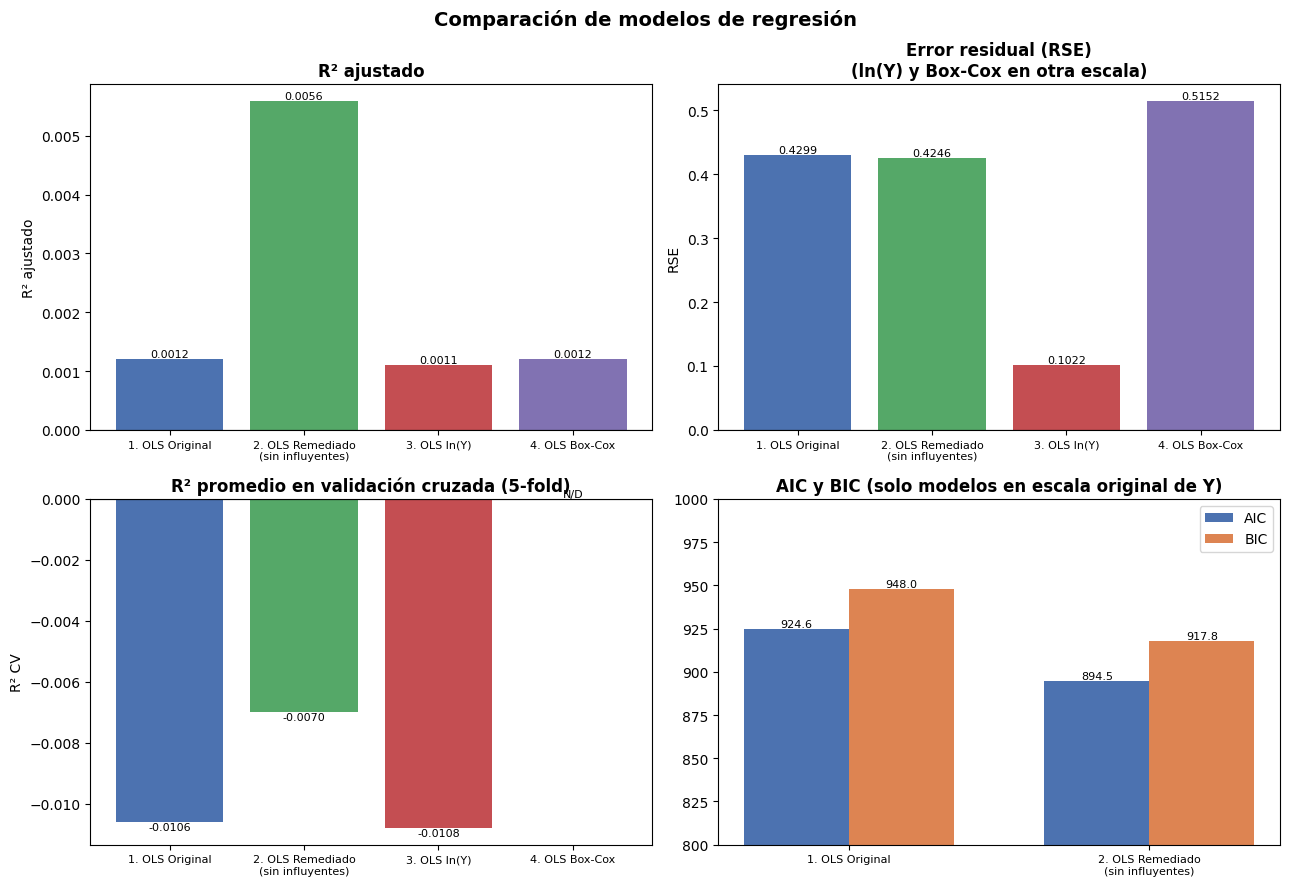

In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Tabla comparativa 2.7 (valores tomados de la salida del análisis)
df = pd.DataFrame({
    "Modelo": ["1. OLS Original", "2. OLS Remediado\n(sin influyentes)",
               "3. OLS ln(Y)", "4. OLS Box-Cox"],
    "n": [800, 791, 800, 800],
    "R2": [0.0062, 0.0106, 0.0061, 0.0062],
    "R2_Aj": [0.0012, 0.0056, 0.0011, 0.0012],
    "AIC": [924.5575, 894.4706, -1373.5838, 1214.2749],
    "BIC": [947.9806, 917.8371, -1350.1608, 1237.6979],
    "RSE": [0.4299, 0.4246, 0.1022, 0.5152],
    "CV_R2": [-0.0106, -0.0070, -0.0108, np.nan],
})

colores = ["#4C72B0", "#55A868", "#C44E52", "#8172B2"]
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

def barras(ax, col, titulo, ylabel, decimales=4):
    vals = df[col]
    b = ax.bar(df["Modelo"], vals.fillna(0), color=colores)
    ax.set_title(titulo, fontweight="bold")
    ax.set_ylabel(ylabel)
    ax.axhline(0, color="black", lw=0.8)
    ax.tick_params(axis="x", labelsize=8)
    for rect, v in zip(b, vals):
        txt = "N/D" if pd.isna(v) else f"{v:.{decimales}f}"
        y = rect.get_height()
        ax.annotate(txt, (rect.get_x() + rect.get_width() / 2, y),
                    ha="center", va="bottom" if y >= 0 else "top", fontsize=8)

barras(axes[0, 0], "R2_Aj", "R² ajustado", "R² ajustado")
barras(axes[0, 1], "RSE", "Error residual (RSE)\n(ln(Y) y Box-Cox en otra escala)", "RSE")
barras(axes[1, 0], "CV_R2", "R² promedio en validación cruzada (5-fold)", "R² CV")

# AIC y BIC agrupados, solo modelos en la escala original de Y
orig = df.iloc[[0, 1]]
x = np.arange(len(orig)); w = 0.35
ax = axes[1, 1]
b1 = ax.bar(x - w/2, orig["AIC"], w, label="AIC", color="#4C72B0")
b2 = ax.bar(x + w/2, orig["BIC"], w, label="BIC", color="#DD8452")
ax.set_xticks(x); ax.set_xticklabels(orig["Modelo"], fontsize=8)
ax.set_title("AIC y BIC (solo modelos en escala original de Y)", fontweight="bold")
ax.set_ylim(800, 1000)
ax.legend()
for rect in list(b1) + list(b2):
    ax.annotate(f"{rect.get_height():.1f}", (rect.get_x() + rect.get_width()/2, rect.get_height()),
                ha="center", va="bottom", fontsize=8)

fig.suptitle("Comparación de modelos de regresión", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("comparacion_modelos.png", dpi=200)
print("Gráfico guardado: comparacion_modelos.png")